# Jezero Krateri ve Salda Gölü: aynı fiziksel ölçekte karşılaştırma

**Planetary Analog Finder · NASA Space Apps Challenge**

Bu notebook projenin ilk çalışan bilimsel bileşenidir. Mars'taki Jezero Krateri ile Dünya'daki Salda Gölü'nü gerçek uydu verisiyle karşılaştırır, sonra Jezero'ya topografik olarak en yakın Dünya bölgelerini küresel olarak arar.

Salda, Jezero'nun **mineralojik** analoğu olarak bilinir. Burada sorduğumuz soru farklı: **arazi biçimi** açısından da benziyor mu? Yöntem bu ayrımı görünür kılmalı.

Tüm yöntem `src/analog_finder/` paketindedir. Veriler ilk çalıştırmada indirilir ve `data/cache/` altında saklanır.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analog_finder.bodies import MARS, EARTH
from analog_finder.catalog import CATALOG_DIR, load_catalog
from analog_finder.dem import read_earth_patch, read_global_patch, Patch
from analog_finder.landcover import window_fractions
from analog_finder.mola_support import shot_counts, shot_coverage
from analog_finder.query import window_features
from analog_finder.similarity import Filters, explain, family_agreement, label_of, rank_candidates
from analog_finder.sites import KNOWN_ANALOGS
from analog_finder.surface import surface_for_window
from analog_finder.terrain import (DEFAULT_SCALES_M, extract_features, feature_names, hillshade,
                                   hypsometric_curve, margin_m, radial_profile, slope_cdf)
from analog_finder.validation import self_retrieval, support_bias, with_track_gaps

WINDOW = 60_000.0
SCALES = DEFAULT_SCALES_M
HALF = WINDOW / 2 + margin_m(SCALES)
JEZERO = (18.38, 77.58)
SALDA = (37.55, 29.68)

EARTH_C, MARS_C, THIRD_C = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 10, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Verileri okuma

Dünya için NASADEM, Mars için MOLA kullanıyoruz. İki kaynakta da yalnızca ilgili bölgenin baytları indirilir. Hiçbir aşamada Mars verisine Dünya koordinat sistemi atanmaz: her gövde kendi yarıçapıyla metre cinsinden işlenir.

In [2]:
jezero_patch = read_global_patch(MARS, *JEZERO, HALF)
salda_patch = read_earth_patch(*SALDA, HALF, arcsec=1)

jezero = extract_features(jezero_patch, *JEZERO, WINDOW, SCALES)
salda = extract_features(salda_patch, *SALDA, WINDOW, SCALES)

pd.DataFrame({
    "Kaynak": [jezero_patch.source, salda_patch.source],
    "Ham piksel K-G (m)": [jezero_patch.native_m, salda_patch.native_m],
    "Satır × sütun": [str(jezero_patch.z.shape), str(salda_patch.z.shape)],
    "En düşük (m)": [np.nanmin(jezero_patch.z), np.nanmin(salda_patch.z)],
    "En yüksek (m)": [np.nanmax(jezero_patch.z), np.nanmax(salda_patch.z)],
}, index=["Jezero (Mars)", "Salda (Dünya)"])

,Kaynak,Ham piksel K-G (m),Satır × sütun,En düşük (m),En yüksek (m)
Jezero (Mars),MGS MOLA MEGDR 128 ppd (USGS global mosaic),463.094,"(159, 168)","-3,043.000",-542.000
Salda (Dünya),nasadem @ 1 arc-sec,30.888,"(2377, 3013)",341.000,"2,522.000"


## 2. Aynı fiziksel ölçekte görünüm

İki panel de 60 km × 60 km alanı, 1 km destekli aynı filtreyle gösterir. Kuzey yukarıdadır.

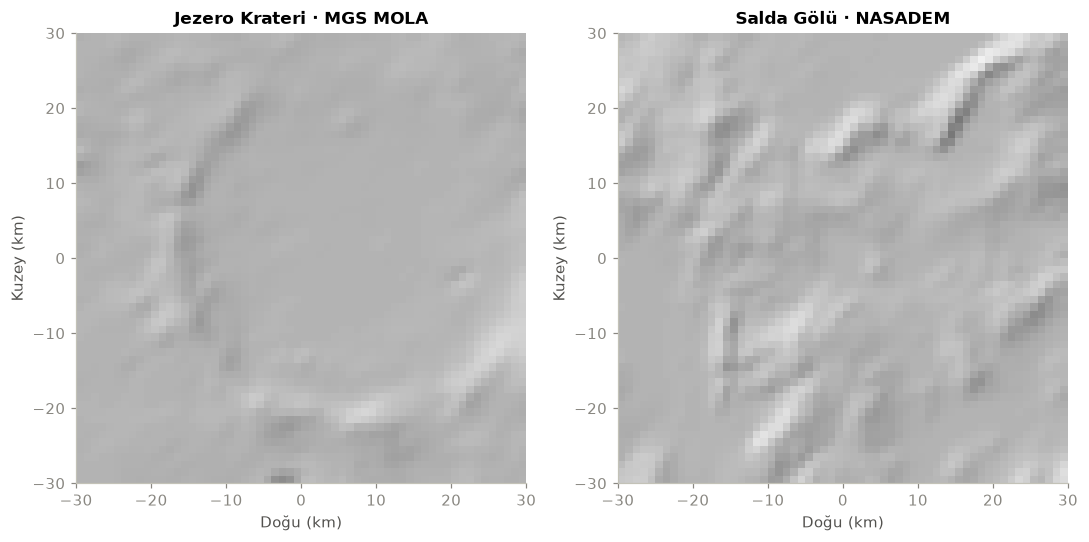

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5.2))
extent = [-30, 30, -30, 30]
for ax, feats, title in zip(axes, (jezero, salda), ("Jezero Krateri · MGS MOLA", "Salda Gölü · NASADEM")):
    ax.imshow(hillshade(feats.grids[1000.0], 1000.0), cmap="gray", extent=extent, vmin=0, vmax=1)
    ax.set_title(title); ax.set_xlabel("Doğu (km)"); ax.set_ylabel("Kuzey (km)"); ax.grid(False)
fig.tight_layout()

## 3. Neden ham pikseller karşılaştırılamaz

Eğim, üzerinde ölçüldüğü mesafeye bağlıdır. Aşağıda aynı Salda arazisinin ortalama eğimi önce 30 m ham pikselden, sonra Jezero ile aynı 1 km destekle hesaplanıyor.

In [4]:
def raw_mean_slope(patch, lat0):
    dy = np.radians(patch.dlat) * patch.body.radius_m
    dx = np.radians(patch.dlon) * patch.body.radius_m * np.cos(np.radians(lat0))
    n = int(WINDOW / 2 / dy)
    cy, cx = patch.z.shape[0] // 2, patch.z.shape[1] // 2
    nx = int(WINDOW / 2 / dx)
    z = patch.z[cy - n:cy + n, cx - nx:cx + nx]
    gy, gx = np.gradient(z, dy, dx)
    return float(np.degrees(np.arctan(np.hypot(gx, gy))).mean())

naive = pd.DataFrame({
    "Ham piksel üzerinde ort. eğim (°)": [raw_mean_slope(jezero_patch, JEZERO[0]), raw_mean_slope(salda_patch, SALDA[0])],
    "1 km destekle ort. eğim (°)": [jezero.values["slope_mean_1km"], salda.values["slope_mean_1km"]],
}, index=["Jezero (463 m)", "Salda (30 m)"])
display(naive)
ham_oran = naive.iloc[1, 0] / naive.iloc[0, 0]
esit_oran = naive.iloc[1, 1] / naive.iloc[0, 1]
print(f"Salda/Jezero eğim oranı: ham {ham_oran:.1f} kat, eşlenmiş destekle {esit_oran:.1f} kat")

,Ham piksel üzerinde ort. eğim (°),1 km destekle ort. eğim (°)
Jezero (463 m),2.812,2.356
Salda (30 m),9.179,3.955


Salda/Jezero eğim oranı: ham 3.3 kat, eşlenmiş destekle 1.7 kat


## 4. Çok ölçekli özellikler

Karşılaştırma mutlak yüksekliği kullanmaz. `Dairesel simetri R²`, yerel eğim çıkarıldıktan sonra yükseklik farklarının ne kadarının merkeze uzaklıkla açıklandığını gösterir; krater benzeri biçimlerde yüksektir. `Havza derinliği` pozitifse merkez kenarlardan alçaktır.

In [5]:
names = feature_names(SCALES)
pd.DataFrame({
    "Özellik": [label_of(n)[0] for n in names], "Birim": [label_of(n)[1] for n in names],
    "Jezero": [jezero.values[n] for n in names], "Salda": [salda.values[n] for n in names],
}).round(3)

,Özellik,Birim,Jezero,Salda
0,Ortalama eğim @ 1 km,°,2.356,3.955
1,Eğim std. sapması @ 1 km,°,2.461,3.285
2,Eğim 95. yüzdelik @ 1 km,°,7.671,10.112
3,Arazi Engebelilik İndeksi @ 1 km,m,33.021,57.209
4,Yerel pürüzlülük @ 1 km,m,14.986,30.486
5,Ortalama eğim @ 2 km,°,1.956,2.893
6,Eğim std. sapması @ 2 km,°,1.903,2.115
7,Eğim 95. yüzdelik @ 2 km,°,6.076,6.748
8,Arazi Engebelilik İndeksi @ 2 km,m,55.888,85.682
9,Yerel pürüzlülük @ 2 km,m,30.262,49.014


Dairesel simetri R²: Jezero 0.58, Salda 0.16


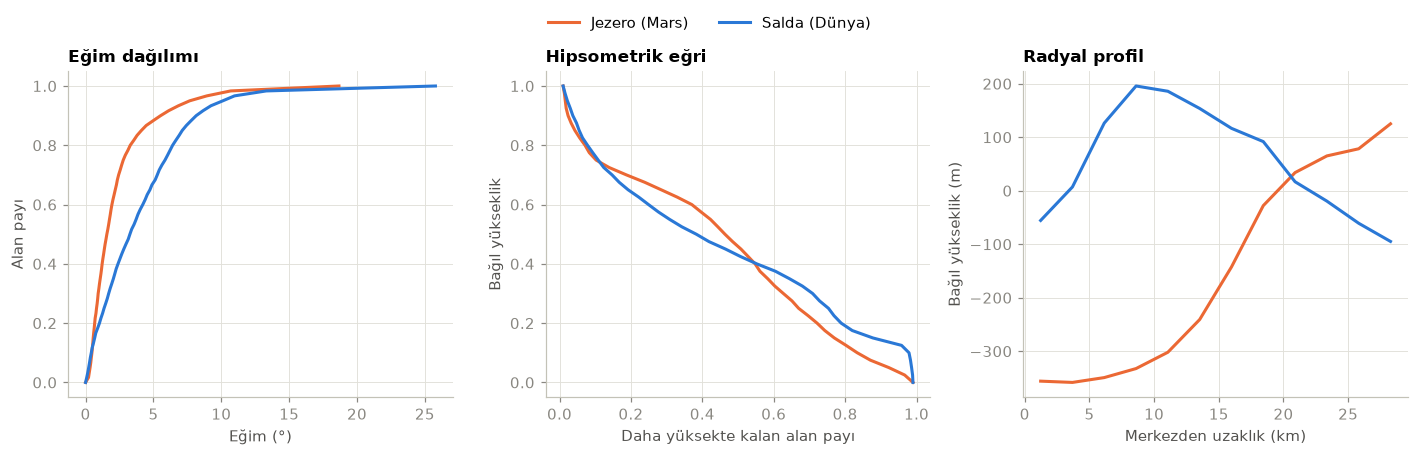

In [6]:
g_j, g_s = jezero.grids[1000.0], salda.grids[1000.0]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))

def two(ax, a, b, xlabel, ylabel, title, percent_x=False):
    ax.plot(*a, color=MARS_C, label="Jezero (Mars)")
    ax.plot(*b, color=EARTH_C, label="Salda (Dünya)")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title, loc="left")

two(axes[0], slope_cdf(g_j, 1000.0), slope_cdf(g_s, 1000.0), "Eğim (°)", "Alan payı", "Eğim dağılımı")
two(axes[1], hypsometric_curve(g_j), hypsometric_curve(g_s), "Daha yüksekte kalan alan payı", "Bağıl yükseklik", "Hipsometrik eğri")
rj, pj, r2j = radial_profile(g_j, 1000.0); rs, ps, r2s = radial_profile(g_s, 1000.0)
two(axes[2], (rj / 1000, pj), (rs / 1000, ps), "Merkezden uzaklık (km)", "Bağıl yükseklik (m)", "Radyal profil")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.07))
fig.tight_layout()
print(f"Dairesel simetri R²: Jezero {r2j:.2f}, Salda {r2s:.2f}")

## 5. Sonuçlara ne kadar güvenebiliriz?

Üç deney yapıyoruz:

1. **Gerçek veri desteği.** MOLA'nın ölçüm sayısı ürünü, her hücreye kaç lazer atımı düştüğünü söyler.
2. **Çözünürlük yanlılığı.** Aynı Salda penceresini 30 m'den ve 15 yay saniyeden (katalogdaki ızgara) hesaplayıp karşılaştırıyoruz.
3. **Kör arama.** Bilinen Dünya pencerelerini gerçek MOLA iz deseniyle bozuyor, sonra sistemin onları tüm katalog içinde yeniden bulup bulamadığına bakıyoruz.

megc44n000hb.img: Jezero penceresindeki hücrelerin %32.9'inde en az bir ölçüm var, hücre başına ortalama 0.60 atım.


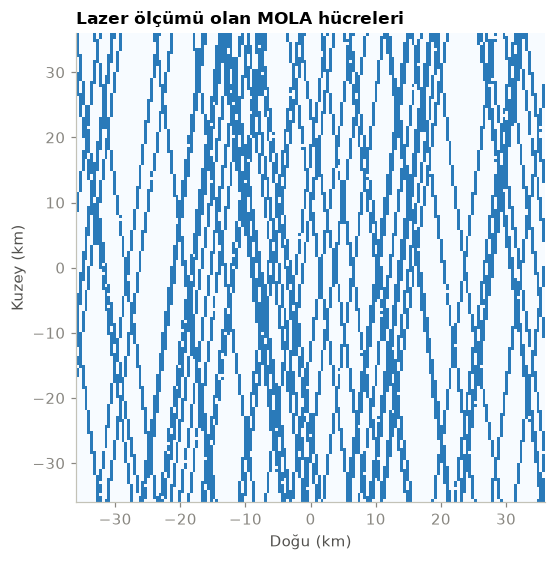

In [7]:
counts, product = shot_counts(*JEZERO, WINDOW + 2 * margin_m(SCALES))
coverage = shot_coverage(*JEZERO, WINDOW)
print(f"{product}: Jezero penceresindeki hücrelerin %{coverage.measured_frac * 100:.1f}'inde en az bir ölçüm var, hücre başına ortalama {coverage.mean_shots:.2f} atım.")

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.imshow(counts > 0, cmap="Blues", vmin=0, vmax=1.4, extent=[-36, 36, -36, 36], interpolation="nearest")
ax.set_title("Lazer ölçümü olan MOLA hücreleri", loc="left"); ax.set_xlabel("Doğu (km)"); ax.set_ylabel("Kuzey (km)"); ax.grid(False)
fig.tight_layout()

In [8]:
salda_15 = read_earth_patch(*SALDA, HALF, arcsec=15)
f15 = extract_features(salda_15, *SALDA, WINDOW, SCALES)
gappy = with_track_gaps(salda_15, counts > 0)
fg = extract_features(gappy, *SALDA, WINDOW, SCALES)

bias = support_bias(salda.values, f15.values).rename(columns={"fine": "30 m kaynak", "coarse": "15 yay sn.", "bias_pct": "Yanlılık %"})
bias["MOLA izi + enterpolasyon"] = [fg.values[n] for n in bias["feature"]]
bias["İz yanlılığı %"] = 100 * (bias["MOLA izi + enterpolasyon"] - bias["15 yay sn."]) / bias["15 yay sn."].abs()
bias["Özellik"] = [label_of(n)[0] for n in bias["feature"]]
bias[["Özellik", "30 m kaynak", "15 yay sn.", "Yanlılık %", "MOLA izi + enterpolasyon", "İz yanlılığı %"]].round(2)

,Özellik,30 m kaynak,15 yay sn.,Yanlılık %,MOLA izi + enterpolasyon,İz yanlılığı %
0,Ortalama eğim @ 1 km,3.950,3.910,-1.190,3.650,-6.540
1,Eğim std. sapması @ 1 km,3.280,3.220,-1.980,2.980,-7.550
2,Eğim 95. yüzdelik @ 1 km,10.110,9.760,-3.440,9.160,-6.230
3,Arazi Engebelilik İndeksi @ 1 km,57.210,56.120,-1.900,51.940,-7.460
4,Yerel pürüzlülük @ 1 km,30.490,29.090,-4.590,24.540,-15.620
5,Ortalama eğim @ 2 km,2.890,2.880,-0.520,2.780,-3.340
6,Eğim std. sapması @ 2 km,2.120,2.100,-0.920,2.010,-4.080
7,Eğim 95. yüzdelik @ 2 km,6.750,6.730,-0.230,6.420,-4.710
8,Arazi Engebelilik İndeksi @ 2 km,85.680,85.190,-0.570,81.620,-4.190
9,Yerel pürüzlülük @ 2 km,49.010,48.310,-1.430,44.860,-7.150


In [9]:
catalog_path = CATALOG_DIR / "earth_global.parquet"
catalog, meta = load_catalog(catalog_path)
print(f"Katalog: {len(catalog):,} geçerli pencere · {meta['failed_dem_tiles'].__len__()} başarısız DEM karosu · {meta['failed_cover_tiles'].__len__()} başarısız WorldCover karosu")

retrieval, changes = self_retrieval(catalog, names, counts > 0, n=400)
print(f"Kör arama, {len(retrieval)} pencere: ilk sırada %{(retrieval['rank'] == 1).mean() * 100:.1f}, ilk 10'da %{(retrieval['rank'] <= 10).mean() * 100:.1f}, ilk 100'de %{(retrieval['rank'] <= 100).mean() * 100:.1f}; medyan sıra {retrieval['rank'].median():.0f}")
changes.assign(Özellik=[label_of(n)[0] for n in changes.index])[["Özellik", "median_abs_change_pct", "p90_abs_change_pct"]].rename(columns={"median_abs_change_pct": "Medyan mutlak değişim %", "p90_abs_change_pct": "90. yüzdelik %"}).round(1)

Katalog: 324,859 geçerli pencere · 0 başarısız DEM karosu · 0 başarısız WorldCover karosu


Kör arama, 399 pencere: ilk sırada %85.7, ilk 10'da %95.7, ilk 100'de %98.5; medyan sıra 1


,Özellik,Medyan mutlak değişim %,90. yüzdelik %
slope_mean_1km,Ortalama eğim @ 1 km,8.500,11.700
slope_std_1km,Eğim std. sapması @ 1 km,9.500,14.200
slope_p95_1km,Eğim 95. yüzdelik @ 1 km,9.000,13.400
tri_1km,Arazi Engebelilik İndeksi @ 1 km,10.000,13.900
rough_1km,Yerel pürüzlülük @ 1 km,17.400,21.700
slope_mean_2km,Ortalama eğim @ 2 km,3.200,6.200
slope_std_2km,Eğim std. sapması @ 2 km,4.200,8.700
slope_p95_2km,Eğim 95. yüzdelik @ 2 km,3.800,8.500
tri_2km,Arazi Engebelilik İndeksi @ 2 km,4.300,7.400
rough_2km,Yerel pürüzlülük @ 2 km,8.300,12.900


## 6. Küresel arama: Jezero'ya en yakın Dünya bölgeleri

Dünya kataloğu 60 km pencerelerden oluşur ve pencereler 20 km adımla kayar. Önce çıplak zemin filtresiyle (WorldCover) arıyoruz, ardından filtresiz sonuçla karşılaştırıyoruz. `Kararlılık`, ağırlıklar rastgele değiştirildiğinde adayın en yakın %0,1 içinde kalma oranıdır.

In [10]:
ranked = rank_candidates(jezero.values, catalog, names, filters=Filters.bare_ground(), top_n=10)
unfiltered = rank_candidates(jezero.values, catalog, names, filters=None, top_n=10)
print(f"Filtreden geçen pencere: {ranked.n_after_filter:,} / {ranked.n_scanned:,}")
print("Dünya'nın olağan aralığı dışında kalan özellikler:", [label_of(n)[0] for n in ranked.out_of_range])

columns = ["rank", "lat", "lon", "distance", "score", "percentile", "stability", "lc_bare", "radial_r2", "basin_depth"]
headers = {"rank": "#", "lat": "Enlem", "lon": "Boylam", "distance": "Mesafe", "score": "Benzerlik", "percentile": "Yüzdelik", "stability": "Kararlılık", "lc_bare": "Çıplak pay", "radial_r2": "Simetri R²", "basin_depth": "Havza (m)"}
display(ranked.table[columns].rename(columns=headers).round(3))
display(unfiltered.table[columns].rename(columns=headers).round(3))

Filtreden geçen pencere: 48,763 / 324,859
Dünya'nın olağan aralığı dışında kalan özellikler: ['Dairesel simetri R²', 'Havza derinliği (kenar − merkez)']


,#,Enlem,Boylam,Mesafe,Benzerlik,Yüzdelik,Kararlılık,Çıplak pay,Simetri R²,Havza (m)
0,1,43.465,91.615,0.208,81.230,99.999,1.000,0.967,0.536,480.790
1,2,33.932,68.999,0.268,76.500,99.998,1.000,0.771,0.526,511.413
2,3,35.551,53.347,0.303,73.823,99.996,1.000,0.786,0.550,424.578
3,4,-22.905,-68.288,0.356,70.031,99.995,1.000,0.983,0.507,389.372
4,5,39.328,92.355,0.368,69.225,99.994,1.000,1.000,0.522,271.570
5,6,45.983,94.599,0.371,69.003,99.994,1.000,0.722,0.453,375.404
6,7,38.429,91.238,0.397,67.262,99.993,1.000,0.999,0.611,296.782
7,8,-22.365,-68.527,0.399,67.073,99.993,1.000,0.981,0.557,313.340
8,9,-26.502,-67.454,0.402,66.919,99.992,1.000,0.989,0.666,600.515
9,10,-21.466,-69.222,0.407,66.554,99.991,0.997,1.000,0.468,383.440


,#,Enlem,Boylam,Mesafe,Benzerlik,Yüzdelik,Kararlılık,Çıplak pay,Simetri R²,Havza (m)
0,1,-8.696,31.159,0.183,83.315,100.000,1.000,0.000,0.522,477.385
1,2,43.465,91.615,0.208,81.230,99.999,1.000,0.967,0.536,480.790
2,3,81.596,-44.857,0.218,80.387,99.999,1.000,0.080,0.521,418.480
3,4,1.736,36.396,0.230,79.458,99.999,1.000,0.268,0.553,444.511
4,5,72.963,-54.383,0.238,78.784,99.998,1.000,0.023,0.608,357.167
5,6,18.644,-98.134,0.256,77.415,99.998,1.000,0.001,0.534,372.548
6,7,77.639,-66.412,0.267,76.566,99.998,1.000,0.055,0.616,585.060
7,8,33.932,68.999,0.268,76.500,99.998,1.000,0.771,0.526,511.413
8,9,65.049,-40.856,0.270,76.302,99.997,1.000,0.050,0.534,499.977
9,10,-0.422,36.123,0.288,75.003,99.997,1.000,0.000,0.504,525.289


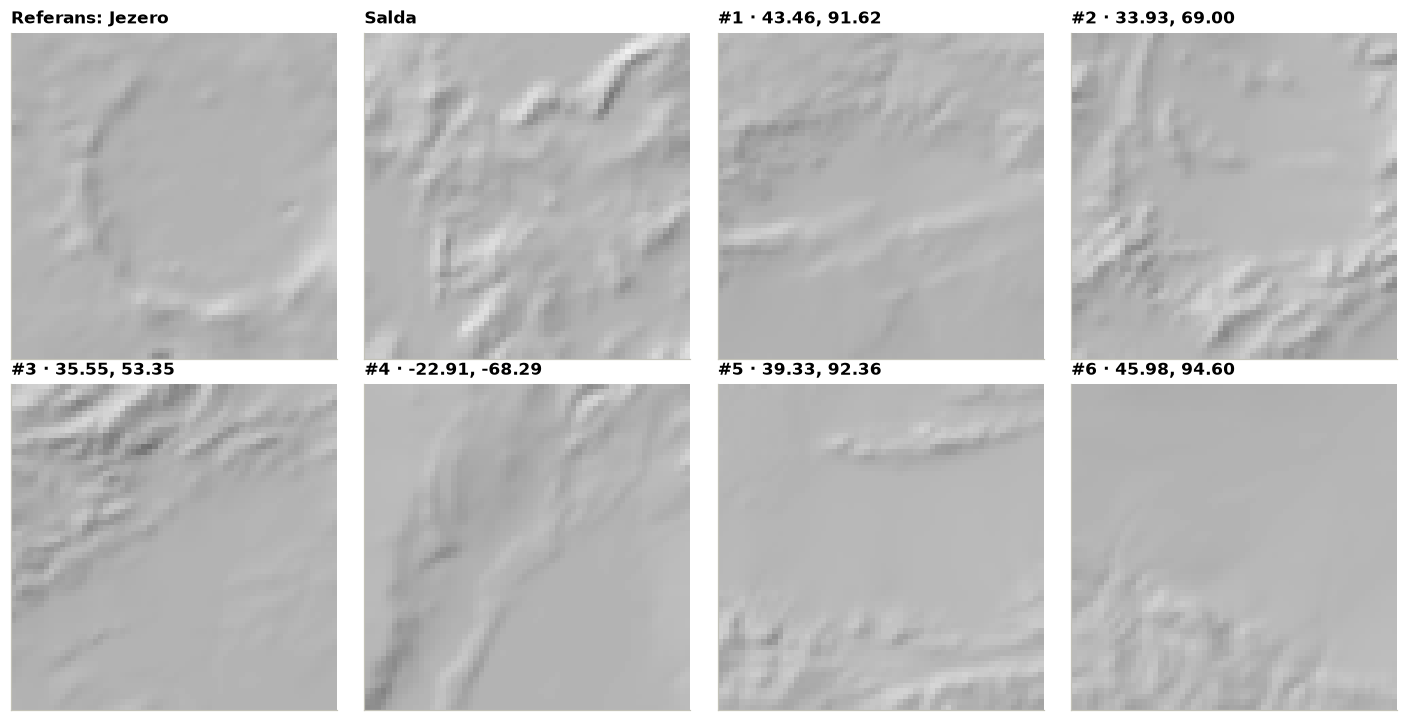

In [11]:
top = ranked.table.head(6)
fig, axes = plt.subplots(2, 4, figsize=(13, 6.6))
axes = axes.ravel()
axes[0].imshow(hillshade(g_j, 1000.0), cmap="gray", extent=extent, vmin=0, vmax=1)
axes[0].set_title("Referans: Jezero", loc="left")
axes[1].imshow(hillshade(g_s, 1000.0), cmap="gray", extent=extent, vmin=0, vmax=1)
axes[1].set_title("Salda", loc="left")
for ax, row in zip(axes[2:], top.itertuples()):
    feats, _ = window_features(EARTH, row.lat, row.lon, WINDOW)
    ax.imshow(hillshade(feats.grids[1000.0], 1000.0), cmap="gray", extent=extent, vmin=0, vmax=1)
    ax.set_title(f"#{row.rank} · {row.lat:.2f}, {row.lon:.2f}", loc="left")
for ax in axes:
    ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

Salda: mesafe 2.39, Dünya pencerelerinin %11.6'inden daha yakın.


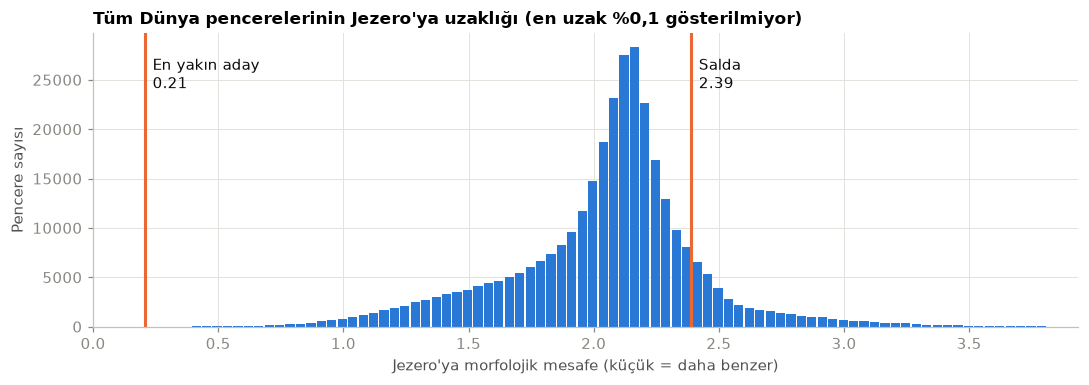

In [12]:
salda_distance, salda_percentile = ranked.locate(f15.values)
best = ranked.table.iloc[0]

fig, ax = plt.subplots(figsize=(10, 3.6))
upper = np.percentile(ranked.sorted_distance, 99.9)
ax.hist(ranked.sorted_distance[ranked.sorted_distance <= upper], bins=90, color=EARTH_C, rwidth=0.88)
ax.set_xlim(0, upper)
ymax = ax.get_ylim()[1]
for value, text in ((best["distance"], f"En yakın aday\n{best['distance']:.2f}"), (salda_distance, f"Salda\n{salda_distance:.2f}")):
    ax.axvline(value, color=MARS_C, linewidth=2)
    ax.text(value + 0.03, ymax * 0.92, text, color="#0b0b0b", va="top")
ax.set_xlabel("Jezero'ya morfolojik mesafe (küçük = daha benzer)"); ax.set_ylabel("Pencere sayısı")
ax.set_title("Tüm Dünya pencerelerinin Jezero'ya uzaklığı (en uzak %0,1 gösterilmiyor)", loc="left"); fig.tight_layout()
print(f"Salda: mesafe {salda_distance:.2f}, Dünya pencerelerinin %{salda_percentile:.1f}'inden daha yakın.")

In [13]:
rows = []
for site in KNOWN_ANALOGS:
    feats, _ = window_features(EARTH, site.lat, site.lon, WINDOW)
    if not np.isfinite(list(feats.values.values())).all():
        rows.append({"Alan": site.name, "Bilinen analog türü": site.note}); continue
    d, p = ranked.locate(feats.values)
    rows.append({"Alan": site.name, "Bilinen analog türü": site.note, "Mesafe": d, "Yüzdelik": p,
                 "Simetri R²": feats.values["radial_r2"], "Havza (m)": feats.values["basin_depth"]})
pd.DataFrame(rows).sort_values("Mesafe").reset_index(drop=True).round(2)

,Alan,Bilinen analog türü,Mesafe,Yüzdelik,Simetri R²,Havza (m)
0,Richat Yapısı,"Morfoloji: dairesel erozyon yapısı, çarpma değil",1.130,97.880,0.660,91.900
1,Mistastin,"Morfoloji: çarpma krateri gölü, 28 km",1.140,97.790,0.480,104.390
2,Death Valley,Kurak havza ve evaporitler,1.250,96.370,0.120,588.510
3,Ries Krateri,"Morfoloji: çarpma krateri, 24 km",1.470,91.690,0.280,56.270
4,McMurdo Kuru Vadileri,İklim: soğuk ve kuru,1.480,91.280,0.060,195.830
5,Atacama – Yungay,İklim: aşırı kuraklık,1.700,84.000,0.070,38.880
6,Gosses Bluff,"Morfoloji: aşınmış çarpma yapısı, 22 km",1.710,83.770,0.110,44.500
7,Haughton Krateri,"Morfoloji: kutupsal çarpma krateri, 23 km",1.750,81.740,0.110,30.880
8,Bosumtwi,"Morfoloji: çarpma krateri gölü, 10,5 km",1.770,81.150,0.160,21.500
9,Vredefort,Morfoloji: çok aşınmış çarpma yapısı,2.100,50.390,0.010,2.350


## 7. En yakın aday neden seçildi?

Aşağıdaki tablo adayla Jezero arasındaki farkın kaynaklarını en büyükten küçüğe sıralar.

In [14]:
print({k: round(v) for k, v in family_agreement(best).items()})
why = explain(ranked, jezero.values, best)
why.assign(Katkı=(why["contribution"] * 100).round(1))[["label", "family", "unit", "reference", "candidate", "Katkı"]].rename(columns={"label": "Özellik", "family": "Aile", "unit": "Birim", "reference": "Jezero", "candidate": "Aday", "Katkı": "Katkı %"}).head(8).round(3)

{'Eğim': 82, 'Engebelilik': 93, 'Rölyef': 89, 'Biçim': 74}


,Özellik,Aile,Birim,Jezero,Aday,Katkı %
0,Dairesel simetri R²,Biçim,,0.585,0.536,32.200
1,Yükseklik çarpıklığı,Biçim,,0.300,0.034,13.300
2,Havza derinliği (kenar − merkez),Biçim,m,429.089,480.790,11.700
3,Eğim std. sapması @ 2 km,Eğim,°,1.903,1.366,9.900
4,Eğim std. sapması @ 4 km,Eğim,°,1.208,0.937,9.200
5,Ortalama eğim @ 4 km,Eğim,°,1.541,1.866,4.600
6,Yükselti farkı (P1–P99),Rölyef,m,957.070,"1,299.239",4.500
7,Hipsometrik integral,Biçim,,0.434,0.411,3.400


## 8. Yüzey katmanı: WorldCover ve Sentinel-2

Topografik benzerlik yüzey örtüsünü söylemez. Salda ve en yakın aday için arazi örtüsüne ve Sentinel-2 göstergelerine bakıyoruz.

,Salda %,En yakın aday %
Çıplak/seyrek,2.200,96.700
Ağaç,32.200,0.000
Çalılık,0.100,0.000
Otlak,34.000,3.300
Tarım,28.400,0.000
Yapılaşma,0.600,0.000
Su,2.600,0.000
Kar/buz,0.000,0.000


,Sahne,Medyan NDVI,"Yeşil pay (NDVI>0,4)",Medyan NDMI,SWIR B11/B12,Kapsama
Salda,S2A_35SQB_20250709_1_L2A,0.287,0.290,-0.010,1.419,1.000
En yakın aday,S2A_46TCP_20250905_0_L2A,0.054,0.000,-0.134,1.056,0.759


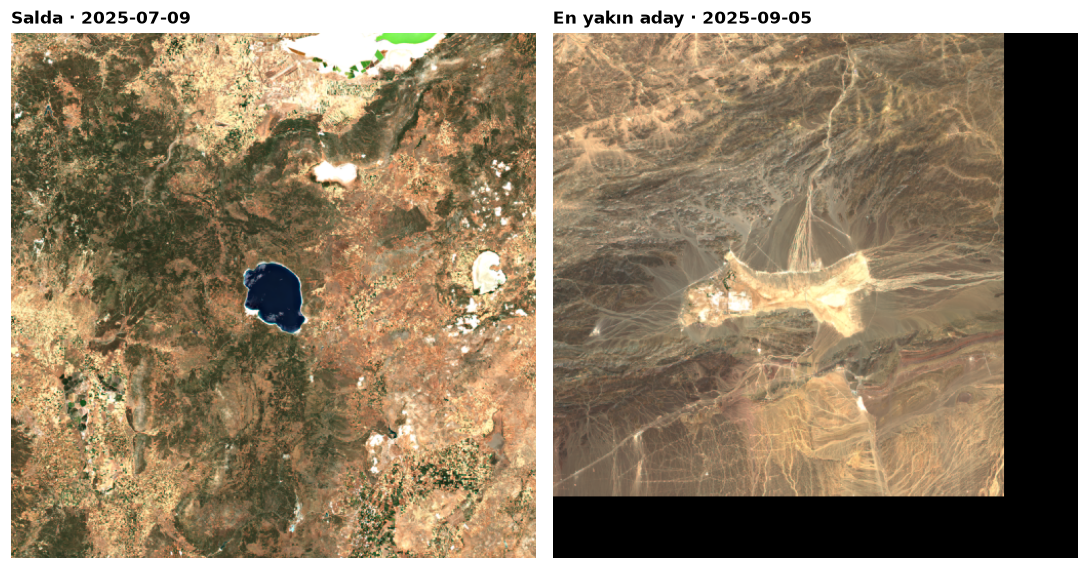

In [15]:
salda_lc = window_fractions(*SALDA, WINDOW)
best_lc = window_fractions(float(best["lat"]), float(best["lon"]), WINDOW)
keys = ["lc_bare", "lc_tree", "lc_shrub", "lc_grass", "lc_crop", "lc_built", "lc_water", "lc_snow"]
names_tr = ["Çıplak/seyrek", "Ağaç", "Çalılık", "Otlak", "Tarım", "Yapılaşma", "Su", "Kar/buz"]
display(pd.DataFrame({"Salda %": [100 * salda_lc[k] for k in keys], "En yakın aday %": [100 * best_lc[k] for k in keys]}, index=names_tr).round(1))

s_salda = surface_for_window(*SALDA, WINDOW)
s_best = surface_for_window(float(best["lat"]), float(best["lon"]), WINDOW)
fig, axes = plt.subplots(1, 2, figsize=(10, 5.2))
summary_rows = {}
for ax, surface, title in zip(axes, (s_salda, s_best), ("Salda", "En yakın aday")):
    if surface is None:
        ax.set_title(f"{title}: sahne yok", loc="left"); ax.axis("off"); continue
    summary, rgb, _ = surface
    ax.imshow(rgb); ax.set_title(f"{title} · {summary.date}", loc="left"); ax.axis("off")
    summary_rows[title] = {"Sahne": summary.scene_id, "Medyan NDVI": summary.ndvi_median, "Yeşil pay (NDVI>0,4)": summary.green_frac, "Medyan NDMI": summary.ndmi_median, "SWIR B11/B12": summary.swir_ratio_median, "Kapsama": summary.coverage}
fig.tight_layout()
pd.DataFrame(summary_rows).T

## 9. Bulgular

**Salda, Jezero'nun mineralojik analoğudur ama topografik analoğu değildir.** 60 km ölçeğinde Salda'nın morfolojik mesafesi 2,39'dur ve Dünya pencerelerinin yalnızca %11,6'sından daha yakındır. Jezero bir havzadır (kenar merkezden 429 m yüksek, dairesel simetri R² 0,58). Salda penceresinde ise merkez kenardan 151 m yüksektir ve simetri zayıftır (R² 0,16). Bu sonuç, mineralojik ve morfolojik benzerliğin ayrı sorular olduğunu sayısal olarak gösterir.

**Ham piksel karşılaştırması farkı yaklaşık iki kat abartır.** Salda'nın ortalama eğimi Jezero'nunkinin ham piksellerde 3,3 katı, aynı 1 km destekle 1,7 katıdır.

**Küresel arama kapalı havzaları buldu.** 324.859 pencereden 48.763'ü çıplak zemin filtresini geçti. En yakın aday Çin'in Sincan bölgesindedir (43,47°K, 91,62°D). İlk 10 adayın 4'ü Atacama/Puna bölgesindedir. Bu adaylar dairesel krater değildir: yöntem dönmeden bağımsız özet istatistikler kullanır, bu yüzden "çevresi yüksek, tabanı düz havza" biçimini bulur. Sentinel-2 görüntüsünde en yakın adayın açık renkli düz bir tabana inen yelpaze ve kanal izleri taşıdığı görülüyor. Bu görsel bir yorumdur, saha veya jeoloji verisiyle doğrulanmamıştır.

**Bilinen analoglarda beklenen yönde bir sinyal var, ancak örnek küçük.** Morfolojileri nedeniyle listelenen 8 alanın medyan yüzdeliği yaklaşık 83, kimya, iklim veya volkanizma nedeniyle listelenen 7 alanınki 37'dir. İstisnalar vardır: Manicouagan pencereden büyük olduğu için düşük (%32), iklim analoğu McMurdo ise yüksek çıkıyor (%91).

**Güvenilirlik.**

| Deney | Sonuç |
|---|---|
| Jezero penceresinde gerçek lazer ölçümü olan hücre | %32,9 |
| 30 m ile 15 yay saniye arası yanlılık | 1 km'de en çok %4,6; 2–4 km'de çoğunlukla %1,5'in altında |
| MOLA iz deseninin özelliklere etkisi (medyan) | 1 km: %8,5–17,4 · 2 km: %3,2–8,3 · 4 km: %1,1–3,0 |
| Kör arama (399 Dünya penceresi, MOLA iziyle bozulmuş) | ilk sırada %85,7 · ilk 10'da %95,7 · medyan sıra 1 |

Kör arama yöntemin üst sınırını gösterir, çünkü sorgu ve katalog aynı gezegenden gelir. Gezegenler arası geçerliliği kanıtlamaz.

**Sınırlamalar.**

- Benzerlik puanı olasılık değildir ve jeoloji veya mineraloji içermez.
- MOLA, 1 km'den küçük yapıları güvenilir biçimde temsil etmez. Jezero'nun deltası gibi birkaç km'lik yapılar için HRSC gerekir.
- Katalog pencereleri 20 km adımla kayar, bu yüzden bir yapının merkezi 14 km'ye kadar kaçabilir.
- Mars ve Ay'da yerçekimi, atmosfer ve aşınma farklıdır. Benzer biçimler farklı süreçlerden doğmuş olabilir.
- Sentinel-2 özeti tek sahneye dayanır ve MGRS karo kenarlarında pencerenin bir kısmını kapsamayabilir.
